# **MÓDULO 17 - Projeto de Credit Score - Parte 1 - Processamento dos dados**


Essa é a primeira etapa do processo de Credit Score que vocês desenvolverão durante nosso curso.
Nessa primeira etapa vocês irão aplicar os passos aprendidos nos módulos de pré processamento para preparar a base de vocês para o desenvolvimento do modelo.

O termo "credit score" se refere a uma pontuação numérica que representa a credibilidade de um indivíduo em termos de cumprimento de obrigações financeiras, como pagar contas de empréstimos, cartões de crédito, entre outros. Essa pontuação é calculada com base em diversas informações financeiras e de crédito do indivíduo, como histórico de pagamentos, níveis de endividamento, tempo de crédito, tipos de crédito utilizados, entre outros.

O objetivo de um modelo de credit score é prever o risco de um indivíduo se tornar inadimplente com suas obrigações financeiras. Em outras palavras, o modelo avalia a probabilidade de um indivíduo não cumprir com os pagamentos de empréstimos ou outros compromissos financeiros. Essa previsão é fundamental para instituições financeiras, como bancos e credores, na tomada de decisão sobre a concessão de crédito. Um modelo de credit score eficaz pode ajudar essas instituições a avaliar o risco de emprestar dinheiro a um determinado indivíduo e, assim, tomar decisões mais informadas sobre a aprovação ou negação de crédito, bem como sobre os termos e condições desses empréstimos.

**Atenção:** Notem que esse projeto é diferente da base que tenho trabalhado com vocês em aula, apesar de se tratar de uma base bancária durante a aula falamos sobre a variável Churn a ser prevista, nesse caso a previsão seria do valor do Score de Crédito.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import seaborn as sns

In [2]:
# Lembrem-se sempre de alterar a importação dos dados de acordo com o diretório de vocês.
df = pd.read_csv("CREDIT_SCORE_PROJETO_PARTE1.csv", delimiter=";")

df.head(10)

,Age,Gender,Income,Education,Marital Status,Number of Children,Home Ownership,Credit Score
0,25.0,Female,"50.000,00",Bachelor's Degree,Single,0,Rented,High
1,30.0,Male,"100.000,00",Master's Degree,Married,2,Owned,High
2,35.0,Female,"75.000,00",Doctorate,Married,1,Owned,High
3,40.0,Male,"125.000,00",High School Diploma,Single,0,Owned,High
4,45.0,Female,"100.000,00",Bachelor's Degree,Married,3,Owned,High
5,50.0,Male,"150.000,00",Master's Degree,Married,0,Owned,High
6,26.0,Female,"40.000,00",Associate's Degree,Single,0,Rented,Average
7,31.0,Male,"60.000,00",Bachelor's Degree,Single,0,Rented,Average
8,NaN,Female,"80.000,00",Master's Degree,Married,2,Owned,High
9,NaN,Male,"105.000,00",Doctorate,Single,0,Owned,High


Legenda dos dados:

*   **Age** : Idade dos nossos clientes.

*   **Income** : Salário Mensal.

*   **Gender** : Gênero.

*   **Education** : Nível de escolaridade dos clientes.

*   **Marital** : Status Civilmente.

*   **Number of Children** : Quantidade de filhos.

*   **Home** : Tipo de residência, alugada ou própria.

*   **Credit Score** : Nossa variável preditora, o score de crédito dos clientes.


# Etapa 1: Relize os passos que vimos no módulo 18, de pré processamento dos dados.

**A) Verifique os tipos de dados, fazendo as transformações quando necessário.**


In [3]:
df.dtypes

Age                   float64
Gender                    str
Income                    str
Education                 str
Marital Status            str
Number of Children      int64
Home Ownership            str
Credit Score              str
dtype: object

In [4]:
# df["Age"] = df["Age"].astype("int") -> precisa de ajuste mas parece ter valores nulos
df["Income"] = df["Income"].str.replace(".", "").str.replace(",", ".").astype("float")

df.dtypes

Age                   float64
Gender                    str
Income                float64
Education                 str
Marital Status            str
Number of Children      int64
Home Ownership            str
Credit Score              str
dtype: object

**B) Verifique se temos colunas com dados faltantes.
Caso existam colunas com dados faltantes faça o tratamento desses dados, excluindo ou substituindo esses valores. Justifique sua escolha.**

In [5]:
# Numero de colunas nulas
df.isnull().sum()

Age                   34
Gender                 0
Income                 0
Education              0
Marital Status         0
Number of Children     0
Home Ownership         0
Credit Score           0
dtype: int64

In [6]:
# Quanto em porcentagem essas linhas representam
df["Age"].isnull().mean() * 100

np.float64(20.73170731707317)

In [7]:
# Detalhes das linhas com idade faltante
df_age_null = df[df["Age"].isnull()]

df_age_null

,Age,Gender,Income,Education,Marital Status,Number of Children,Home Ownership,Credit Score
8,NaN,Female,80000.0,Master's Degree,Married,2,Owned,High
9,NaN,Male,105000.0,Doctorate,Single,0,Owned,High
10,NaN,Female,90000.0,High School Diploma,Married,1,Owned,High
11,NaN,Male,135000.0,Bachelor's Degree,Married,0,Owned,High
12,NaN,Female,35000.0,High School Diploma,Single,0,Rented,Low
13,NaN,Male,55000.0,Associate's Degree,Single,0,Rented,Average
14,NaN,Female,70000.0,Bachelor's Degree,Married,2,Owned,High
15,NaN,Male,95000.0,Master's Degree,Single,0,Owned,High
16,NaN,Female,85000.0,Doctorate,Married,1,Owned,High
17,NaN,Male,125000.0,High School Diploma,Married,0,Owned,High


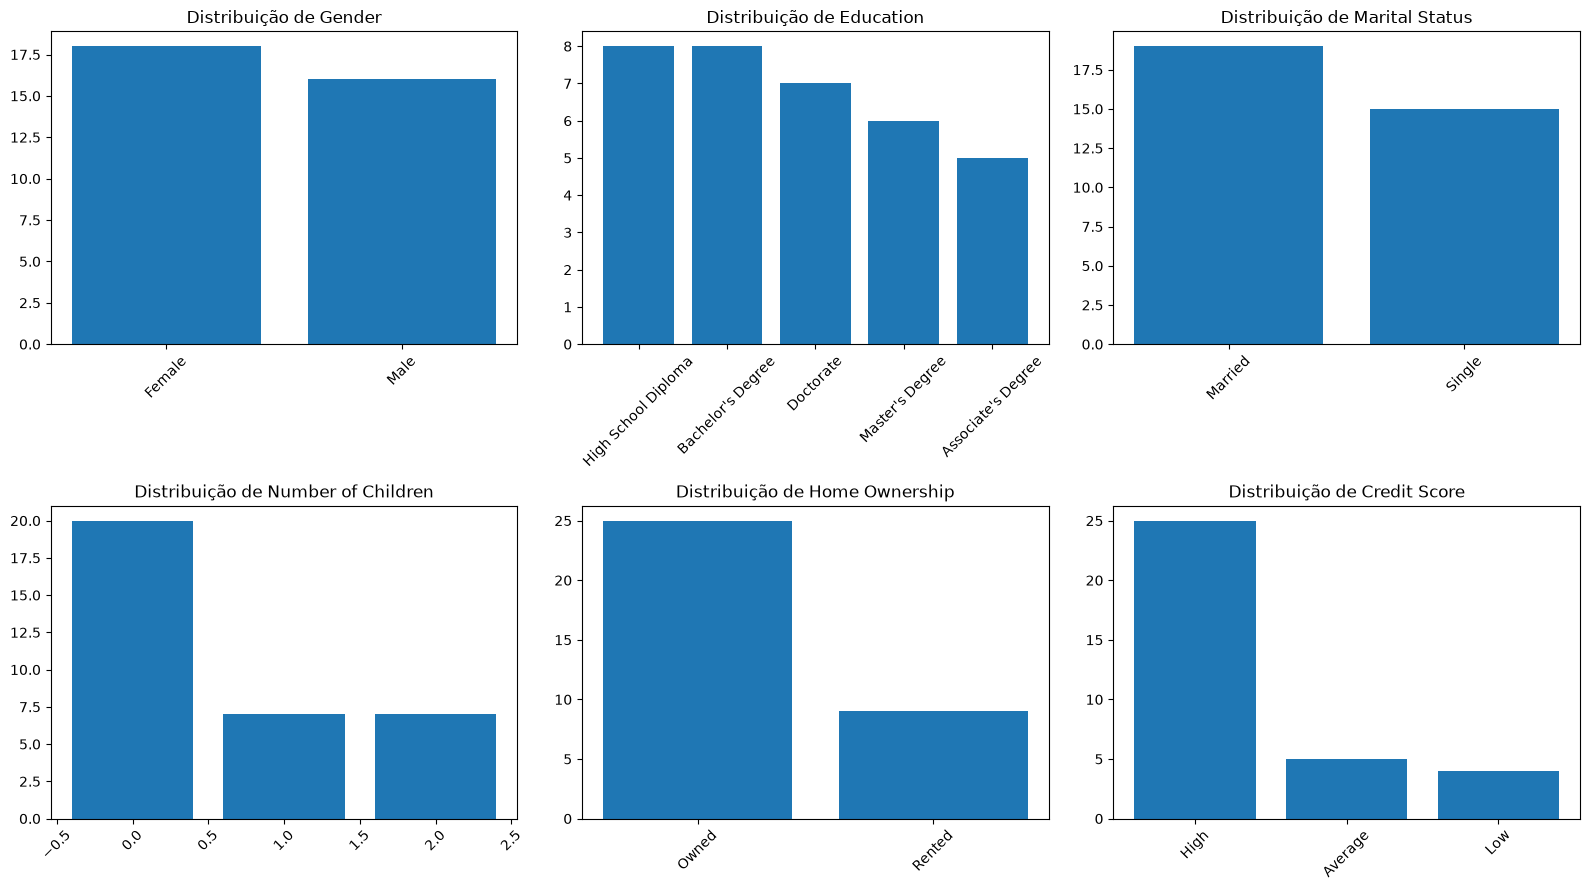

In [8]:
# Checagem para confirmar se existe padrão nas linhdas com dados faltantes
categories = [  # colunas categóricas
    "Gender",
    "Education",
    "Marital Status",
    "Number of Children",
    "Home Ownership",
    "Credit Score",
]


def plotbar(arr):  # função para o loop de plotbar
    plt.bar(arr.index, arr.values)


# Tamanho do plot
plt.figure(figsize=(16, 9))

# loop para subplots
for i in range(len(categories)):  # range pra index e subplot position
    plt.subplot(2, 3, i + 1)
    plt.title(f"Distribuição de {categories[i]}")
    plotbar(df_age_null[categories[i]].value_counts())
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Nos graficos acima fica bem evidente como a remoção de 20% dos dados que as linhas com idade nula representa, podem afetar a análise.
Justo na coluna chave que queremos fazer a predição, as colunas com idade falntante possui em maioria o Score High.
Ou seja, iriamos remover ~25 perfis que se encaixam como High, sem contar a distribuição de donos de casas próprias e com nehuma criança.
Ou seja, acredito que a melhor solução seria a de preencher os dados de idade.

count    130.000000
mean      37.507692
std        8.500110
min       25.000000
25%       30.000000
50%       36.000000
75%       45.000000
max       53.000000
Name: Age, dtype: float64


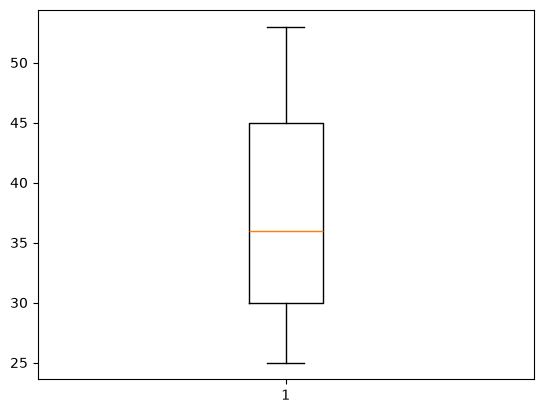

In [9]:
# df com idades validas
df_age_validas = df[df["Age"].notnull()]

# conferindo detalhes da coluna
print(df_age_validas["Age"].describe())

# plot da candle
plt.boxplot(df_age_validas["Age"])
plt.show()

Podemos ver acima que apesar da distribuição se concentrar pouco mais acima da mediana, o .dercribe indica que a Média (~37) e Mediana (36), não são tão distantes.
Acredito que a escolha de qualquer uma das duas seria valida para preservar a integridade do df. Eu vou optar pela média pois acredito que ela vai ser a que vai ter menor impacto geral.

In [10]:
# Ajustando o typo da coluna agora que ela esta sem valores nulos.
df["Age"] = df["Age"].fillna(df["Age"].mean()).astype(int)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 164 entries, 0 to 163
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 164 non-null    int64  
 1   Gender              164 non-null    str    
 2   Income              164 non-null    float64
 3   Education           164 non-null    str    
 4   Marital Status      164 non-null    str    
 5   Number of Children  164 non-null    int64  
 6   Home Ownership      164 non-null    str    
 7   Credit Score        164 non-null    str    
dtypes: float64(1), int64(2), str(5)
memory usage: 10.4 KB


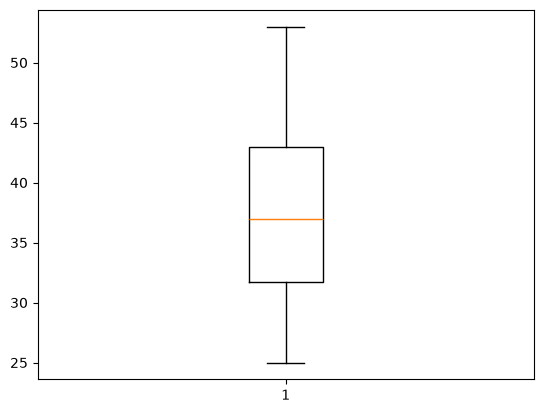

In [11]:
# Conferindo distribuição após ajuste
plt.boxplot(df["Age"])
plt.show()

Colunas com tipos de dados ajustados, sem dados nulos e sem perda de pontos de dado importantes que pudessem prejudicara coluna de target do projeto.

**C) Verifique se temos valores digitados de forma incorreta nas variáveis categóricas que necessitem de tratamento.**

In [12]:
# Agora com as colunas com dados corretos eu posso selecionar caso tipo seja str
df_cat = df.select_dtypes(str)

# Print das colunas categóricas e seus valores unicos
for col in df_cat:
    print(f"{col}\n {df[col].unique()} \n")

Gender
 <StringArray>
['Female', 'Male']
Length: 2, dtype: str 

Education
 <StringArray>
[  'Bachelor's Degree',     'Master's Degree',           'Doctorate',
 'High School Diploma',  'Associate's Degree']
Length: 5, dtype: str 

Marital Status
 <StringArray>
['Single', 'Married']
Length: 2, dtype: str 

Home Ownership
 <StringArray>
['Rented', 'Owned']
Length: 2, dtype: str 

Credit Score
 <StringArray>
['High', 'Average', 'Low']
Length: 3, dtype: str 



Ao que parece, não existem erros de digitação, duplicatas ou similar dentro dos colunas categoricas.

# Etapa 2: Relize os passos que vimos no módulo 15, de análise.

**A) Realiza a análise univariada, aplique a função describe ao nosso dataframe para verificar os dados das variáveis numéricas, se encontrar a possível presença de outliers analise com gráficos a distribuição dos dados.Traga insights sobre os dados analisados.**

In [13]:
df.describe()

,Age,Income,Number of Children
count,164.000000,164.000000,164.000000
mean,37.402439,83765.243902,0.652439
std,7.564625,32457.306728,0.883346
min,25.000000,25000.000000,0.000000
25%,31.750000,57500.000000,0.000000
50%,37.000000,83750.000000,0.000000
75%,43.000000,105000.000000,1.000000
max,53.000000,162500.000000,3.000000


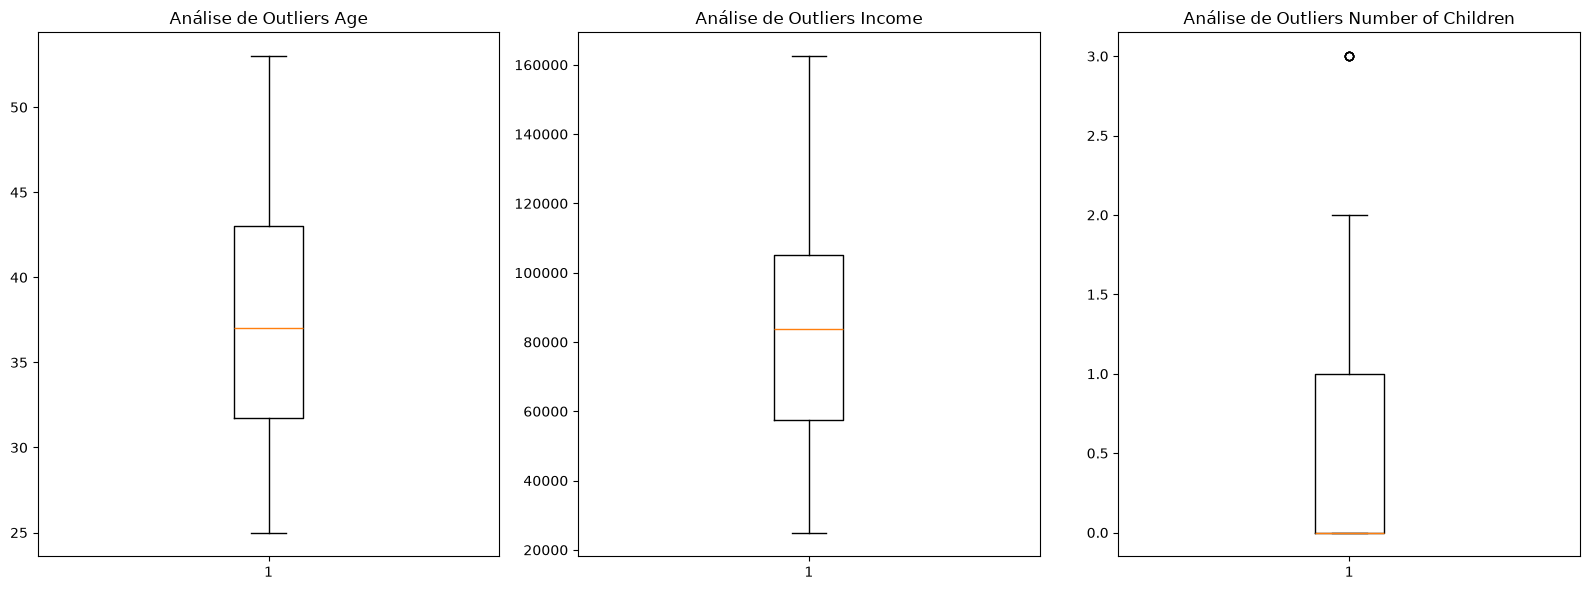

In [14]:
# Checagem de outliers de colunas numéricas
df_num_cols = df.select_dtypes(include=["number"]).columns

# loop para plotagem das boxplot
plt.figure(figsize=(16, 6))
for i in range(len(df_num_cols)):
    plt.subplot(1, len(df_num_cols), i + 1)
    plt.title(f"Análise de Outliers {df_num_cols[i]}")
    plt.boxplot(df[df_num_cols[i]])

plt.tight_layout()
plt.show()

Como podemos ver acima a unica coluna com "Outliers" é a coluna de "Number of Children", mas podemos ignorar, ja que não estamos falando de 30 ou 10 crianças. 3 crianças é um numero perfeitamente normal, provavelmente esse resultado se da pelo range ser pequenoe e a maior parte da concentração e mediana estarem no 0.

**B) Agora realize a análise univariada para as variaveis categóricas, plote gráficos para entender a distribuição das categorias e tente retirar insights de cada gráfico.**

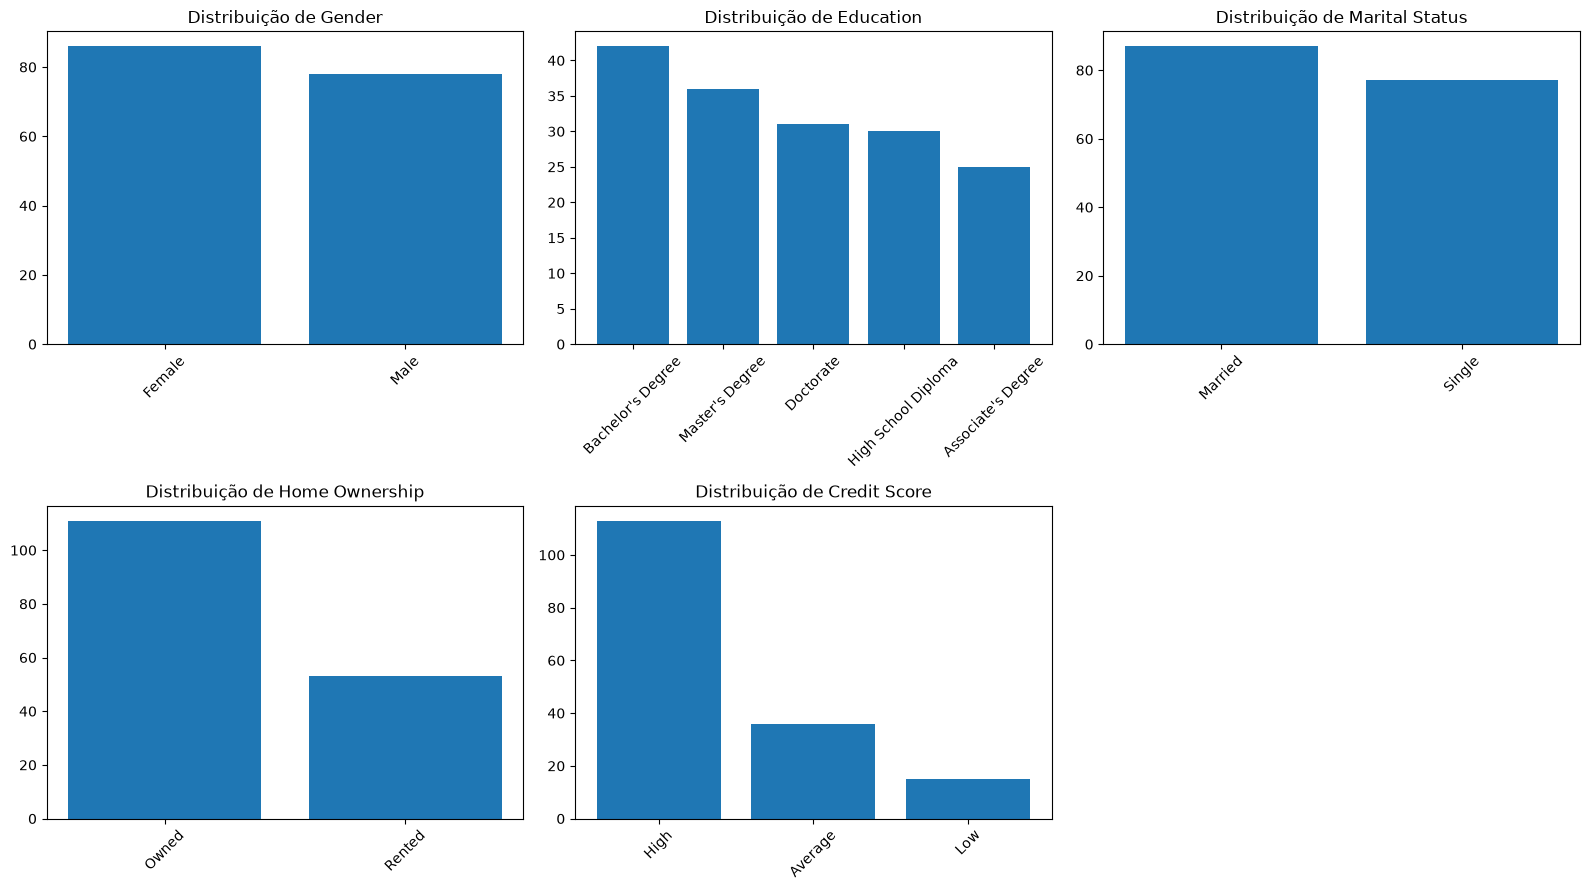

In [15]:
df_cat_cols = df.select_dtypes(str).columns

# Tamanho do plot
plt.figure(figsize=(16, 9))

# loop para subplots
for i in range(len(df_cat_cols)):  # range pra index e subplot position
    plt.subplot(2, 3, i + 1)
    plt.title(f"Distribuição de {df_cat_cols[i]}")
    plotbar(df[df_cat_cols[i]].value_counts())
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Claramente temos uma distribuição bem saudavel de dados, com diferenças pequenas entre categorias, com as mais evidentes sendo a Home Ownership e em Credit Score.
Para credit score pode ser um problema, pois isso pode criar um viés no modelo, mas por agora seguirei em frente.

**C) Você encontrou alguma coluna com outliers?
Se sim realize o tratamento desses casos.**

In [16]:
# seu código aqui

A unica coluna que encontrei com outliers foi a coluna de Number of Children, e acredito que não haja necessidade de alterar ela, ja que o valor de outlier é aceitavel, 3 crianças para um casal é um numero perfeitamente normal.

**D) Realize a análise Bivariada.
Tente responder as seguintes perguntas com gráficos seguidos de insights:**



*   Existe relação entre a idade e o status civil?
*   Qual a relação entre o score de crédito e o nível de escolaridade?
*  O salário parece influenciar na idade?
* O salário parece influenciar no Score de Crédito?
* Clientes com casa própria tendem a ter um score mais alto?



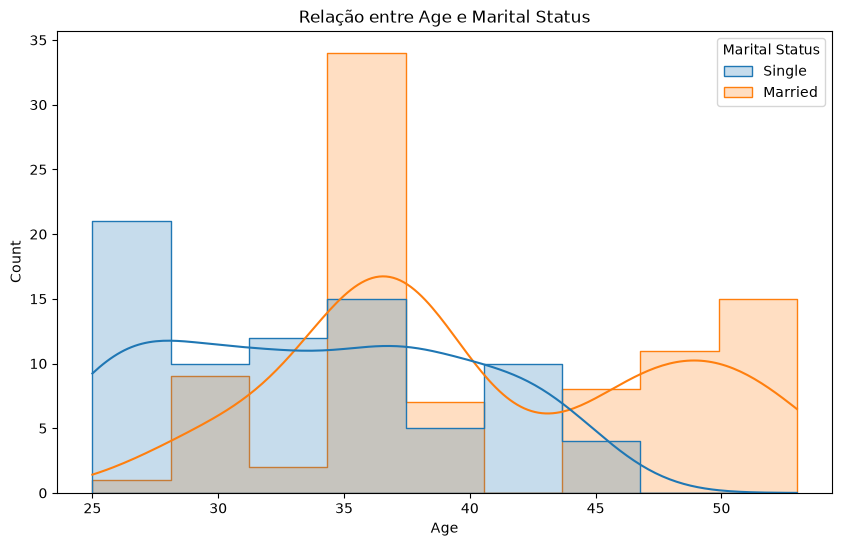

In [17]:
# Relação entre colunas Age e Marital Status
plt.figure(figsize=(10, 6))

sns.histplot(data=df, x="Age", hue="Marital Status", element="step", kde=True)
plt.title("Relação entre Age e Marital Status")
plt.show()

Acima podemos ver que o status civil (Em especial o Single) possui uma relação clara com a idade, esse status cai com o tempo de chegando a 0 depois dos 45.

Em contra partida o status de Marriedparece ter variações bem drasticas, com o vão entre 40 e 45 completamente vazio.

Em termos prativos, como podemos ver com as linhas de tendencia, as pessoas solteiras pouco a pouco deixam de fazer parte do grafico dando espaço a pessoas casadas.

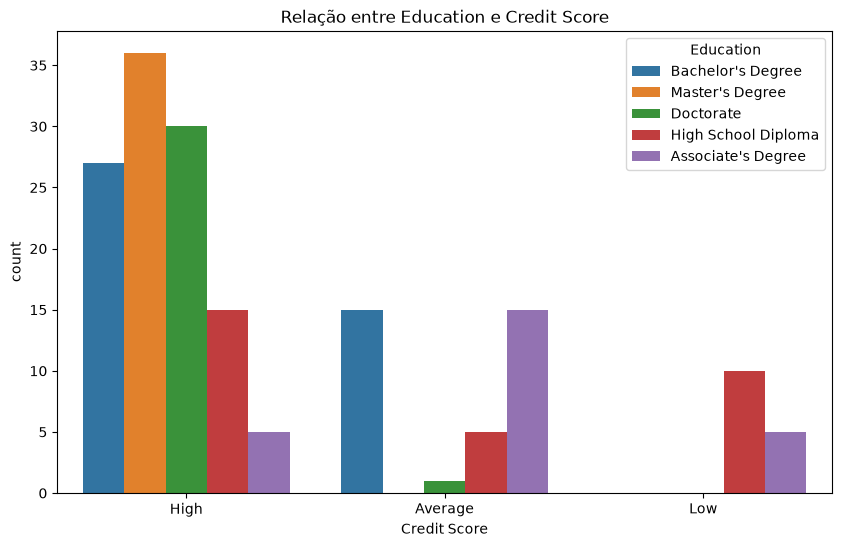

In [18]:
plt.figure(figsize=(10, 6))

sns.countplot(data=df, x="Credit Score", hue="Education")
plt.title("Relação entre Education e Credit Score")
plt.show()

Existe uma relação muito clara entre o nivel de educação e o score que a pessoa possui, com o Low sendo populado exclusivamente por pessoas no ensino médio e com Associate's Degree, enquanto toda a população de Mestrado, quase toda a de doutorado e a maior parcela do Bacharelado estando no high.

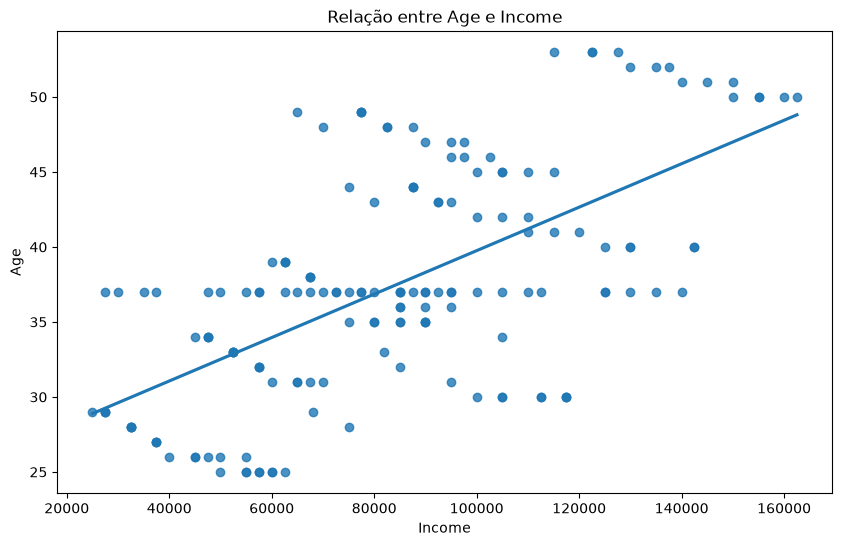

In [19]:
# Relação salário idade
plt.figure(figsize=(10, 6))

# Plot de scatter com regressão linear para indicar relação entre colunas numericas
plt.title("Relação entre Age e Income")
sns.regplot(data=df, x="Income", y="Age", ci=None)
plt.show()

Idade e salário possuem uma relação linear. A relanão não é perfeita, a distrivuição não forma uma escalada perfeita, mas podemso notar como a demografia mais velha é a que popula os salários anuais mais altos. Dos $100,000.00 para cima, a população abaixo ddos 30 é minoria.

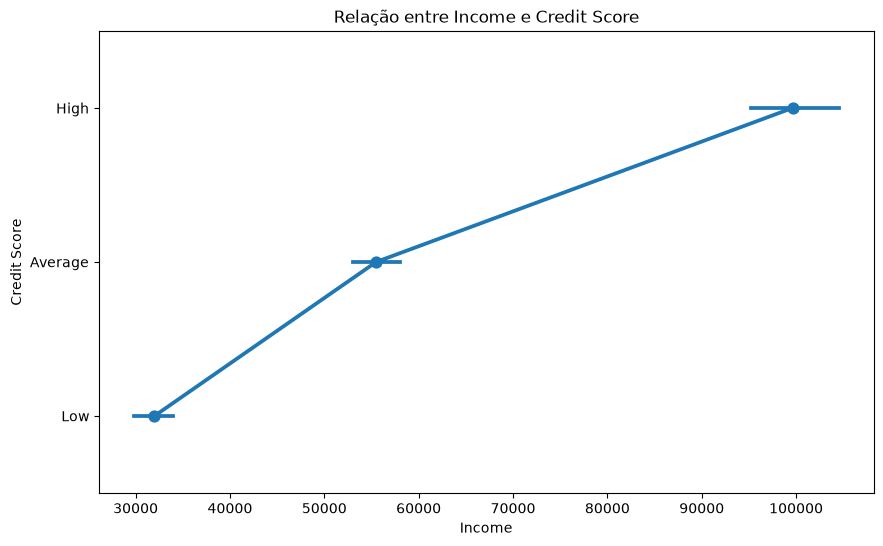

In [20]:
# Relação salário e credit score
plt.figure(figsize=(10, 6))

# Plot de pointplot
plt.title("Relação entre Income e Credit Score")
sns.pointplot(data=df, x="Income", y="Credit Score")
plt.show()

Aqui temos uma visão clara de como o salário interfere no credit score.
É interessante notar como de low para average, temos um degrau mais baixo, com uma inclinação maio na linha do grafico que indica que sair do Low para Average é mais cimples que de Average para High.

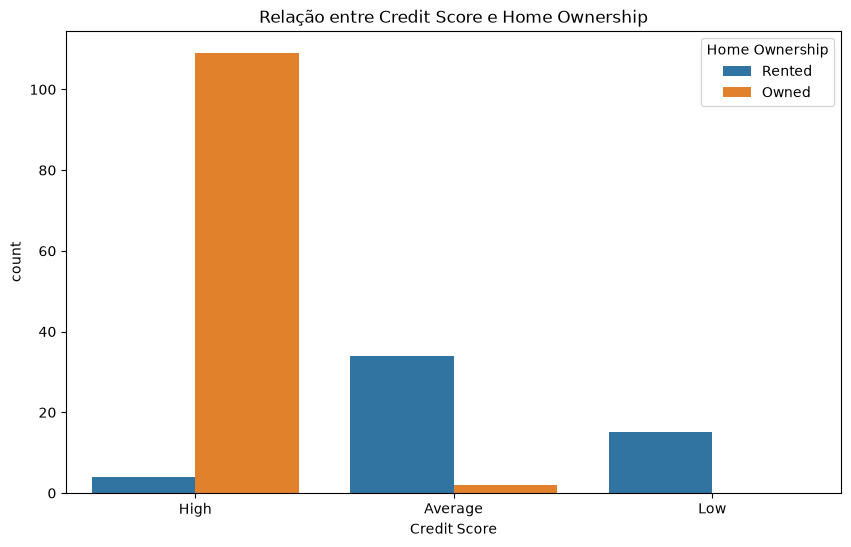

In [21]:
# Relação casa propria e credit score
plt.figure(figsize=(10, 6))

# Plot de pointplot
plt.title("Relação entre Credit Score e Home Ownership")
sns.countplot(data=df, x="Credit Score", hue="Home Ownership")
plt.show()

No grafico anterior eu notei como que havia uma resistencia maior ao salário interferindo no credit score, muito provavelmente isso se da pelo que o grafico aqui mostra.
Presumo que a casa seja o maior diferencial para um credit score High, o que indicaria o porque do salario interferir menos no credit score parasso o Average.

**E) Que outras perguntas te parecem fazer sentido explorarmos a resposta para conhecermos mais nossa base de dados e o comportamento dos clientes?**

 Elabore mais 3 perguntas e responda utilizando gráficos + insights.

Como o Gênero afeta o Credit Score?

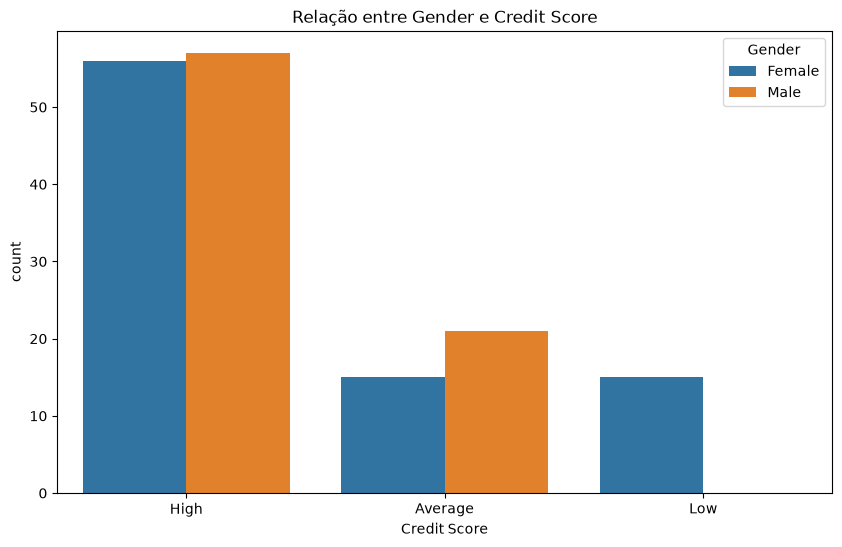

In [22]:
plt.figure(figsize=(10, 6))

# Plot de pointplot
plt.title("Relação entre Gender e Credit Score")
sns.countplot(data=df, x="Credit Score", hue="Gender")
plt.show()

Apesar de o crédito estar bem próximo nas categorias Average e High, a low possui a presença apenas da demografia feminina.
Isso pode se dar a fatores de diferença salarial entre generos.
Vejamos a seguir.

Qual a relação entre genero e salário?

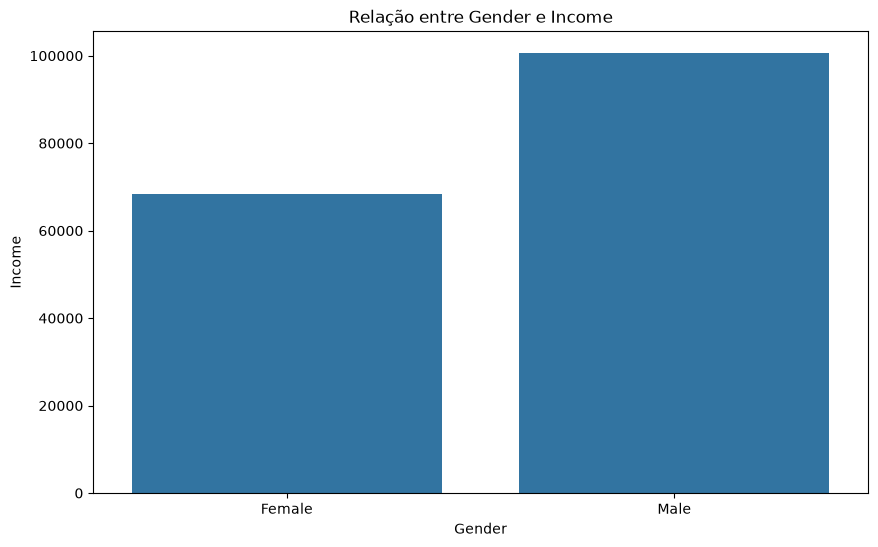

In [23]:
plt.figure(figsize=(10, 6))

# Plot de pointplot
plt.title("Relação entre Gender e Income")
sns.barplot(data=df, x="Gender", y="Income", errorbar=None)
plt.show()

Como eu desconfiava.
Anteriormente vimos como o salário afeta o score, especialmente entre os scores de Low e Average, com a demografia feminina recebendo aproximadamente 35% a menos que homens, isso acaba criando uma dificuldade maior e retenção do publico feminino dentro dos scores mais baixos.

Como é a distribuição de gênero e nivel de educação?

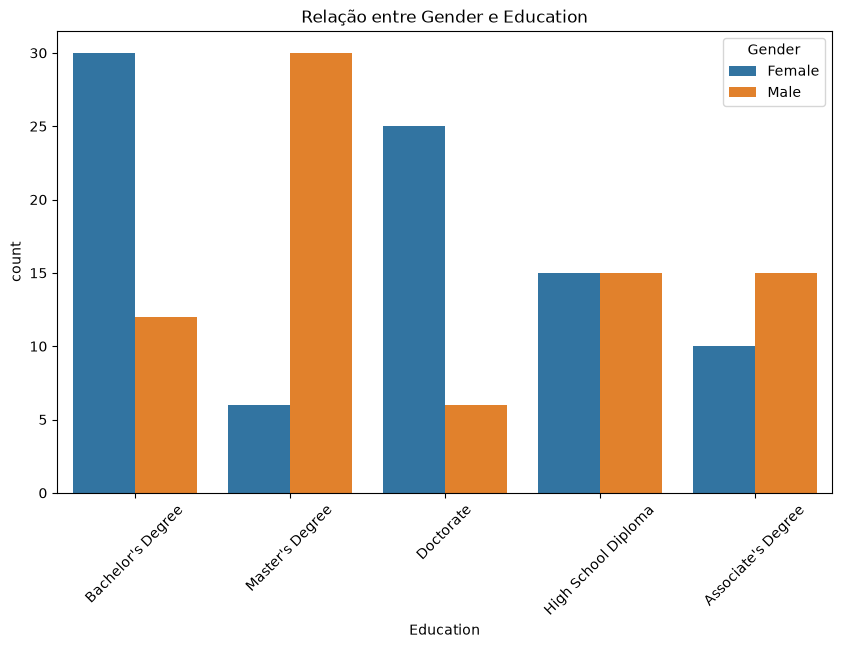

In [24]:
plt.figure(figsize=(10, 6))

# Plot de pointplot
plt.title("Relação entre Gender e Education")
sns.countplot(data=df, x="Education", hue="Gender")
plt.xticks(rotation=45)
plt.show()

Ja na distribuição de educação o grafico esta razoavelmente equilibrado.
Apesar do genero masculino ser dominante nos mestrados, podemso ver uma presença muito maior do genero feminino no Bacharelado e doutorado, onde as mulheres são muito mais presentes que homens.

Porém é interessante notar como a presença feminina se acumula formetemente em formações de alto nivel em relação aos homens e seus salários ainda sim são substancialmente menores, com a distribuição acima poderiamos ao menos esperar que ambos tivessem salários iguais.

Grafico extra para uma visão mais unificada da descoberta.

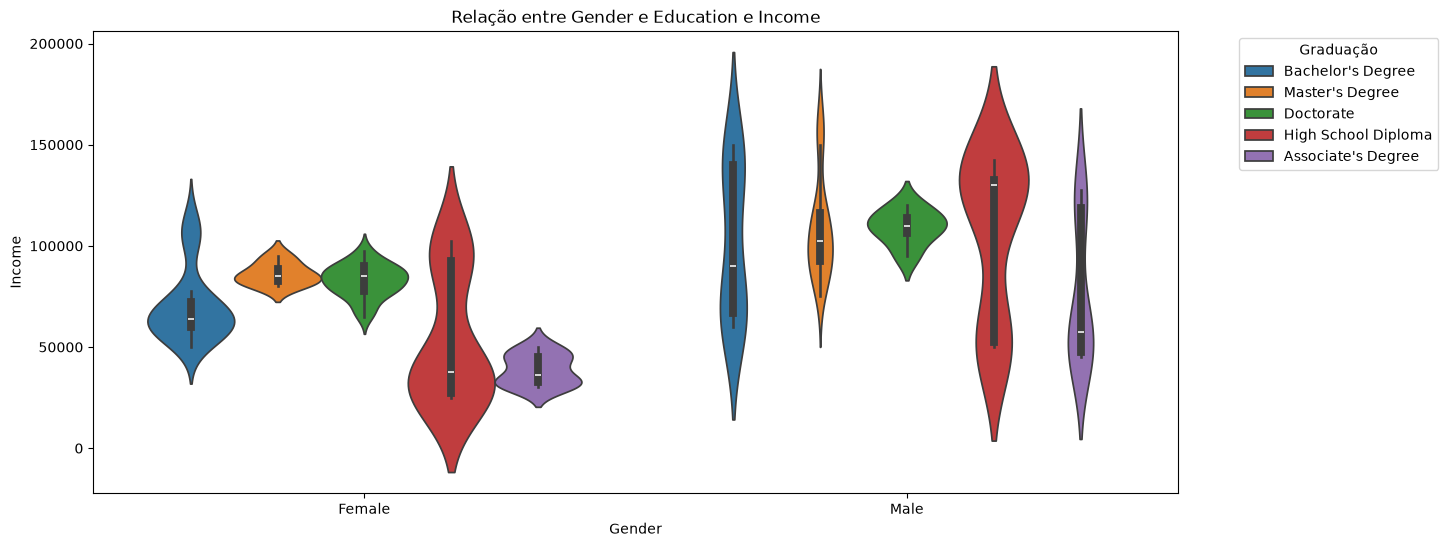

In [25]:
plt.figure(figsize=(14, 6))

# Plot de pointplot
plt.title("Relação entre Gender e Education e Income")
sns.violinplot(data=df, x="Gender", y="Income", hue="Education")
plt.legend(
    title="Graduação",
    bbox_to_anchor=(
        1.05,
        1,
    ),  # Posição (X, Y): 1.05 joga para a direita
)
plt.show()

Por fim, neste grafico temos uma visão *muito* mais clara de como existe um teto de vidro para mulheres, que consequentemente leva elas a scores mais baixos, colocando a demografia feminina em posições mais vulneráveis de Low score.

Note a concentração alta de salários para homens com a formação de High School Degree, a mais baixa, na zona dos ~ $150,000.00 enquanto mulheres com Masters degree e Doctorates, se encontram abaixo dos ~ $100,000.00, com a população feminina de High School Degree, a mesma que a dos homens com a maior concentração salarial alta, possuem sua maior concentração abaixo dos $50,000.00.

# Etapa 3: Relize os passos que vimos no módulo 17, de Correlação, Balanceamento, atributos categóricos e divisão base treino e teste.

**A) Vamos começar pela análise de correlação, plote da forma que achar melhor a análise de correlação, seja pela tabela ou pelo gráfico da matriz.**

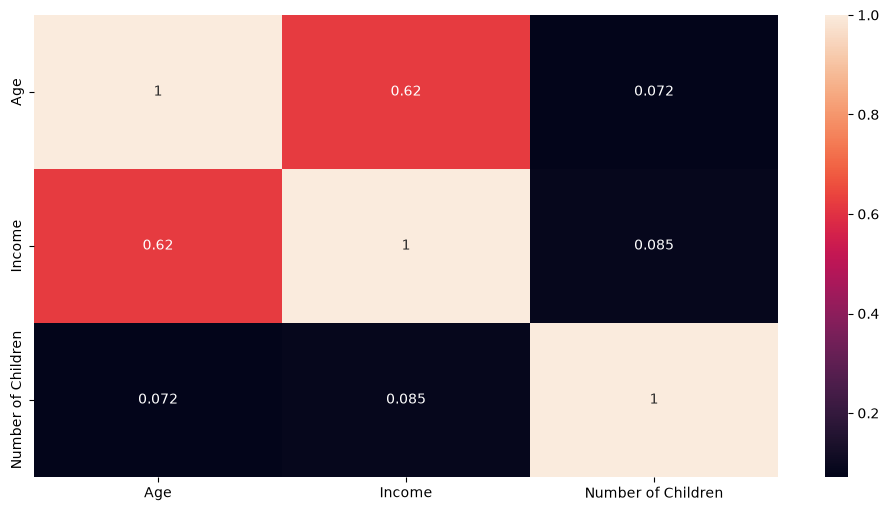

In [ ]:
df_num = df.select_dtypes(["number"])

df_corr = df.corr(numeric_only=True)

plt.figure(figsize=(12, 6))
sns.heatmap(df_corr, annot=True)

plt.show()

**B) Você encontrou variáveis que tem uma média ou alta correlação? Se sim, quais? Te parece fazer sentido essas variáveis terem alta correlação? Justifique.**

Sim, a relação entre salario anual e idade tem uma correlação de 0.62, que reflete bem o grafico de age income plotado anteriormente, que mostra como a idade interfere no salário.

**C) Temos muitos atributos categóricos nessa base, não? Vamos realizar a o tratamento desses atributos utilizando Label Encoder ou one hot. Após, exclua as colunas categóricas.**

In [27]:
# Primeiramente, transformar as colunas categóricas em texto
# Colunas binárias: Gender / Marital Status / Home Ownership
df["Gender_bin"] = df["Gender"].map({"Female": 0, "Male": 1})

df["Marital Status_bin"] = df["Marital Status"].map({"Married": 0, "Single": 1})

df["Home Ownership_bin"] = df["Home Ownership"].map({"Owned": 0, "Rented": 1})

# Colunas Ordinais: Education e Credit Score
df["Education_bin"] = df["Education"].map(
    {
        "High School Diploma": 0,
        "Associate's Degree": 1,
        "Bachelor's Degree": 2,
        "Master's Degree": 3,
        "Doctorate": 4,
    }
)

df["Credit Score_bin"] = df["Credit Score"].map({"Low": 0, "Average": 1, "High": 2})

df.head()

,Age,Gender,Income,Education,Marital Status,Number of Children,Home Ownership,Credit Score,Gender_bin,Marital Status_bin,Home Ownership_bin,Education_bin,Credit Score_bin
0,25,Female,50000.0,Bachelor's Degree,Single,0,Rented,High,0,1,1,2,2
1,30,Male,100000.0,Master's Degree,Married,2,Owned,High,1,0,0,3,2
2,35,Female,75000.0,Doctorate,Married,1,Owned,High,0,0,0,4,2
3,40,Male,125000.0,High School Diploma,Single,0,Owned,High,1,1,0,0,2
4,45,Female,100000.0,Bachelor's Degree,Married,3,Owned,High,0,0,0,2,2


In [28]:
# Confirmando se a operação saiu correta
df_num = df.select_dtypes(["number"])

# Print das colunas numericas e seus valores unicos
for col in df_num:
    print(f"{col}\n {df[col].unique()} \n")

Age
 [25 30 35 40 45 50 26 31 37 43 48 53 29 34 39 44 49 36 41 46 51 27 32 42
 47 52 28 33 38] 

Income
 [ 50000. 100000.  75000. 125000. 150000.  40000.  60000.  80000. 105000.
  90000. 135000.  35000.  55000.  70000.  95000.  85000.  30000.  65000.
 115000.  25000.  45000. 130000. 155000. 110000. 140000.  37500.  57500.
  72500.  32500.  52500.  67500.  92500.  82500. 122500.  27500.  47500.
  62500.  87500.  77500. 112500. 117500. 142500. 160000.  97500. 145000.
 162500. 120000. 102500. 137500. 127500.  82000.  68000.] 

Number of Children
 [0 2 1 3] 

Gender_bin
 [0 1] 

Marital Status_bin
 [1 0] 

Home Ownership_bin
 [1 0] 

Education_bin
 [2 3 4 0 1] 

Credit Score_bin
 [2 1 0] 



**D) Vamos plotar novamente a correlação, agora observando com as variáveis categóricas. Identifique se temos novas variáveis com forte correlação.**

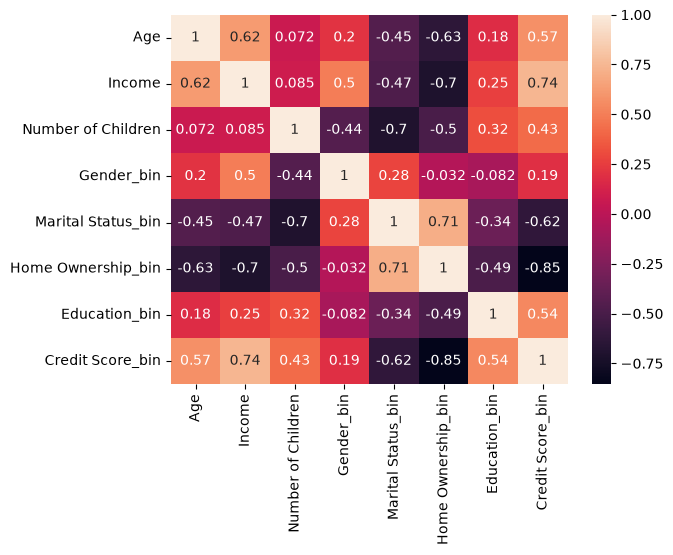

In [34]:
df_corr = df.corr(numeric_only=True)

plt.figure()
sns.heatmap(df_corr, annot=True)

plt.show()

**F) Faça a separação da base em treino e teste e verifique utilizando shape:**

In [30]:
# seu código aqui

**G) É hora de verificar se nossa coluna de Score de crédito está balanceada, verifique através de um gráfico e traga sua opinião acerca do balanceamento.**

In [31]:
# seu código aqui

**H) Vamos realizar o balancecamento dos dados da coluna de credit score.**
Se lembre que realizazmos apenas para a base de treino.

In [32]:
# seu código aqui